In [120]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.optimize import curve_fit
from scipy.stats import landau, norm, trim_mean, trimboth, trim1

import warnings
warnings.filterwarnings('ignore')


In [121]:
def get_data_det(file_name, num1, num2):
    file = ROOT.TFile.Open(file_name)
    detdir = file.Get("VirtualDetector")

    detname = "det_" + str(num1) + "." + str(num2)

    # print(detname)
    
    df_det = ROOT.RDataFrame(detname, detdir)

    X = df_det.AsNumpy(columns=["x"])["x"]
    Y = df_det.AsNumpy(columns=["y"])["y"]
    Z = df_det.AsNumpy(columns=["z"])["z"]
    PX = df_det.AsNumpy(columns=["Px"])["Px"]
    PY = df_det.AsNumpy(columns=["Py"])["Py"]
    PZ = df_det.AsNumpy(columns=["Pz"])["Pz"]
    T = df_det.AsNumpy(columns=["t"])["t"]
    eventID = df_det.AsNumpy(columns=["EventID"])["EventID"]
    parentID = df_det.AsNumpy(columns=["ParentID"])["ParentID"]
    

    x = X[parentID == 0]
    y = Y[parentID == 0]
    z = Z[parentID == 0]
    px = PX[parentID == 0]
    py = PY[parentID == 0]
    pz = PZ[parentID == 0]
    t = T[parentID == 0]
    event = eventID[parentID == 0]

    return [x, y, z, px, py, pz, t, event]

def get_data_trace(filename, trackname):
    file = ROOT.TFile.Open(filename)
    detdir = file.Get("Trace")

    detname = str(trackname)

    # print(detname)
    
    df_det = ROOT.RDataFrame(detname, detdir)

    X = df_det.AsNumpy(columns=["x"])["x"]
    Y = df_det.AsNumpy(columns=["y"])["y"]
    Z = df_det.AsNumpy(columns=["z"])["z"]
    PX = df_det.AsNumpy(columns=["Px"])["Px"]
    PY = df_det.AsNumpy(columns=["Py"])["Py"]
    PZ = df_det.AsNumpy(columns=["Pz"])["Pz"]
    T = df_det.AsNumpy(columns=["t"])["t"]
    parentID = df_det.AsNumpy(columns=["ParentID"])["ParentID"]
    Pathlength = df_det.AsNumpy(columns=["PathLength"])["PathLength"]
    

    x = X[parentID == 0]
    y = Y[parentID == 0]
    z = Z[parentID == 0]
    px = PX[parentID == 0]
    py = PY[parentID == 0]
    pz = PZ[parentID == 0]
    t = T[parentID == 0]
    pathlength = Pathlength[parentID == 0]

    return [x, y, z, px, py, pz, t, pathlength]

In [122]:
m_mu = 105.7 # MeV/c^2
c = 299.792 # mm/ns
filename = "det_in_gap/1e6_bunch_3layers/g4beamline.root"

n_layers = 3
cell_list = []
x_list  = []
y_list  = []
z_list  = []
px_list = []
py_list = []
pz_list = []
t_list  = []
event_list = []
vals_temp = []
for cell in np.arange(0,61):
    
    if(cell%5==2 or cell%5==4):
        idx = int(np.floor((cell%5)/4)+2*np.floor(cell/5))
        print(f'cell {cell}, index {idx}' )
        cell_list.append(cell)
        x_list.append([])
        y_list.append([])
        z_list.append([])
        px_list.append([])
        py_list.append([])
        pz_list.append([])
        t_list.append([])
        event_list.append([])
        
        for i in np.arange(0,2*n_layers):
                vals_temp = get_data_det(filename,cell,i)
                x_list[idx].append(vals_temp[0])
                y_list[idx].append(vals_temp[1])
                z_list[idx].append(vals_temp[2])
                px_list[idx].append(vals_temp[3])
                py_list[idx].append(vals_temp[4])
                pz_list[idx].append(vals_temp[5])
                t_list[idx].append(vals_temp[6])
                event_list[idx].append(vals_temp[7])

cell 2, index 0
cell 4, index 1
cell 7, index 2
cell 9, index 3
cell 12, index 4
cell 14, index 5
cell 17, index 6
cell 19, index 7
cell 22, index 8
cell 24, index 9
cell 27, index 10
cell 29, index 11
cell 32, index 12
cell 34, index 13
cell 37, index 14
cell 39, index 15
cell 42, index 16
cell 44, index 17
cell 47, index 18
cell 49, index 19
cell 52, index 20
cell 54, index 21
cell 57, index 22
cell 59, index 23


In [ ]:
n_traces = 10000
filename_trace = "traces/g4beamline.root"
trace_x_list = []
trace_y_list = []
trace_z_list = []
trace_t_list = []
trace_pl_list = []
for k in np.arange(1,n_traces):
    if (k%1000==0): print(k)
    vals_temp = get_data_trace(filename_trace,"Ev"+str(k)+"Trk0")
    # vals_temp = get_data_trace("12layers_bunch/g4beamline.root","Ev"+str(k)+"Trk0")
    trace_x_list.append(vals_temp[0])
    trace_y_list.append(vals_temp[1])
    trace_z_list.append(vals_temp[2])
    trace_t_list.append(vals_temp[6])
    trace_pl_list.append(vals_temp[7])
    
vals_temp = get_data_trace(filename_trace,"ReferenceParticle")
# vals_temp = get_data_trace("12layers_bunch/g4beamline.root","ReferenceParticle")
trace_x_list.append(vals_temp[0])
trace_y_list.append(vals_temp[1])
trace_z_list.append(vals_temp[2])
trace_t_list.append(vals_temp[6])
trace_pl_list.append(vals_temp[7])

trace_arrays = []

for i in np.arange(0,n_traces):
    trace_arrays.append([])
    trace_arrays[i].append(trace_x_list[i])
    trace_arrays[i].append(trace_y_list[i])
    trace_arrays[i].append(trace_z_list[i])
    trace_arrays[i].append(trace_t_list[i])
    trace_arrays[i].append(trace_pl_list[i])

trace_arrays_np = []

for tr in trace_arrays:
    arr = np.asarray(tr)  # shape (5, N)
    trace_arrays_np.append(arr)

1000
2000


In [ ]:
def track_length_path(track, z1, z2):
    x, y, z, t, pl = track

    # sort
    order = np.argsort(t)
    z = z[order]
    pl = pl[order]

    # handle edge cases
    if len(z) < 2:
        return 0

    # interpolate PathLength at boundaries
    L1 = np.interp(z1, z, pl)
    L2 = np.interp(z2, z, pl)

    return L2 - L1

In [ ]:
z_det_avgs = []
for idx in np.arange(0,24):
    mean_z_A = np.median(z_list[idx][0])
    mean_z_B = np.median(z_list[idx][3])
    z_det_avgs.append([mean_z_A,mean_z_B])
    # print(f"z detector group positions in cell {cell}: {mean_z_A:.2f} to {mean_z_B:.2f}")

cell_trlen_avgs_path = []
cell_trlen_stdev = []
cell_trlen_norm_avgs = []
cell_trlen_median = []


for idx in np.arange(0,24):
    cell_lens_path = []
    for trace_num in np.arange(0,n_traces):

        if (np.max(trace_z_list[trace_num]) >= z_det_avgs[idx][1]) and (np.min(trace_z_list[trace_num]) <= z_det_avgs[idx][0]):
            
            track_len_path = track_length_path(trace_arrays_np[trace_num],z_det_avgs[idx][0],z_det_avgs[idx][1])

            if(track_len_path != 0):
                cell_lens_path.append(track_len_path)
            
    trim_frac = 0.0
    path_trim = trimboth(cell_lens_path,trim_frac)

    
    cell_trlen_avgs_path.append(np.mean(path_trim))
    cell_trlen_stdev.append(np.std(path_trim))
    cell_trlen_norm_avgs.append(np.mean(path_trim)/(z_det_avgs[idx][1] - z_det_avgs[idx][0]))
    cell_trlen_median.append(np.median(path_trim))
    print(idx)
         

In [ ]:
def gaussian(x, mu, sigma, A):
    return A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)

def get_gaussian_params(t_vals, num_t_bins):
    t_mean = np.mean(t_vals)
    t_spread = 5*np.std(t_vals)

    lower_bounds_gauss = [1, 0.001, 1.0]
    upper_bounds_gauss = [1000, 20.0, 4000000.0]
      # lower_bounds_gauss = [0, 0.001, 1.0]
        # upper_bounds_gauss = [100000, 10.0, 40000.0]

    hist_counts_func, bin_edges = np.histogram(
        t_vals,
        range=(t_mean - t_spread, t_mean + t_spread),
        bins=num_t_bins
    )

    bin_centers_func = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    mu_init = bin_centers_func[np.argmax(hist_counts_func)]
    sigma_init = np.std(bin_centers_func)
    A_init = np.max(hist_counts_func)

    # print(f'initial guess: {[mu_init, sigma_init, A_init]}')

    params_gauss, covariance_gauss = curve_fit(
        gaussian,
        bin_centers_func,
        hist_counts_func,
        p0=[mu_init, sigma_init, A_init],
        bounds=(lower_bounds_gauss,upper_bounds_gauss)
    )

    mu, sigma, A = params_gauss

    mu_unc = np.nan
    try:
        mu_unc = np.sqrt(np.diag(covariance_gauss))[0]
    except ValueError:
        pass

    return mu, sigma, A, mu_unc, bin_centers_func, hist_counts_func

def cut_on_radius(rcut,x_in,y_in,t_in):
    
    r = np.sqrt((x_in-np.mean(x_in))**2 + (y_in-np.mean(y_in))**2)
    
    mask = r > rcut  # keep only points OUTSIDE the circle
    
    return x_in[mask], y_in[mask], t_in[mask]


def digitize_return_first_hits(pixel_sizesize,x_in,y_in,t_in):
    
    size_x = 81.5
    # binsize_x = pixel_sizesize # mm
    bins_x = int(2*size_x / pixel_sizesize)
    
    x_edges = np.linspace(-size_x, size_x, bins_x + 1)
    y_edges = np.linspace(-size_x, size_x, bins_x + 1)
    
    # digitize gives bin index (1..bins), subtract 1 → (0..bins-1)
    ix = np.digitize(x_in, x_edges) - 1
    iy = np.digitize(y_in, y_edges) - 1
    
    valid = (ix >= 0) & (ix < bins_x) & (iy >= 0) & (iy < bins_x)
    ix, iy, t_in = ix[valid], iy[valid], t_in[valid]
    
    pixel_id = ix * bins_x + iy
    
    order = np.argsort(t_in)
    pixel_id_sorted = pixel_id[order]
    t_sorted = t_in[order]
    
    _, first_indices = np.unique(pixel_id_sorted, return_index=True)
    t_first_hits = t_sorted[first_indices]

    return t_first_hits

def digitize_return_only_single_hits(pixel_size_in,x_in,y_in,t_in):
    
    size_x = 81.5
    # binsize_x = pixel_sizesize # mm
    bins_x = int(2*size_x / pixel_size_in)
    
    x_edges = np.linspace(-size_x, size_x, bins_x + 1)
    y_edges = np.linspace(-size_x, size_x, bins_x + 1)
    
    # digitize gives bin index (1..bins), subtract 1 → (0..bins-1)
    ix = np.digitize(x_in, x_edges) - 1
    iy = np.digitize(y_in, y_edges) - 1

    t_in = np.asarray(t_in)
    
    valid = (ix >= 0) & (ix < bins_x) & (iy >= 0) & (iy < bins_x)
    ix, iy, t_in = ix[valid], iy[valid], t_in[valid]
    
    pixel_id = ix * bins_x + iy

    order = np.argsort(pixel_id)
    pixel_id_sorted = pixel_id[order]
    t_sorted = t_in[order]
    
    # Get unique pixel IDs along with counts and the index of first occurrence
    unique_ids, first_indices, counts = np.unique(
        pixel_id_sorted, return_index=True, return_counts=True
    )
    
    # Keep only pixels that were hit exactly once
    single_hit_mask = counts == 1
    single_hit_indices = first_indices[single_hit_mask]
    
    t_single_hits = t_sorted[single_hit_indices]
    
    return t_single_hits

def digitize_return_single_hits_pos(pixel_size_in,x_in,y_in,t_in):
    
    size_x = 81.5
    # binsize_x = pixel_sizesize # mm
    bins_x = int(2*size_x / pixel_size_in)
    
    x_edges = np.linspace(-size_x, size_x, bins_x + 1)
    y_edges = np.linspace(-size_x, size_x, bins_x + 1)
    
    # digitize gives bin index (1..bins), subtract 1 → (0..bins-1)
    ix = np.digitize(x_in, x_edges) - 1
    iy = np.digitize(y_in, y_edges) - 1

    t_in = np.asarray(t_in)
    
    valid = (ix >= 0) & (ix < bins_x) & (iy >= 0) & (iy < bins_x)
    ix, iy, t_in = ix[valid], iy[valid], t_in[valid]
    
    pixel_id = ix * bins_x + iy

    order = np.argsort(pixel_id)
    pixel_id_sorted = pixel_id[order]
    t_sorted = t_in[order]
    x_sorted = x_in[order]
    y_sorted = y_in[order]
    
    # Get unique pixel IDs along with counts and the index of first occurrence
    unique_ids, first_indices, counts = np.unique(
        pixel_id_sorted, return_index=True, return_counts=True
    )
    
    # Keep only pixels that were hit exactly once
    single_hit_mask = counts == 1
    single_hit_indices = first_indices[single_hit_mask]
    
    t_single_hits = t_sorted[single_hit_indices]

    x_single_hits = x_sorted[single_hit_indices]
    y_single_hits = y_sorted[single_hit_indices]

    return x_single_hits, y_single_hits, t_single_hits

def digitize_return_single_hits_all_vars(pixel_size_in,x_in,y_in,px_in,py_in,pz_in,t_in):
    
    size_x = 81.5
    # binsize_x = pixel_sizesize # mm
    bins_x = int(2*size_x / pixel_size_in)
    
    x_edges = np.linspace(-size_x, size_x, bins_x + 1)
    y_edges = np.linspace(-size_x, size_x, bins_x + 1)
    
    # digitize gives bin index (1..bins), subtract 1 → (0..bins-1)
    ix = np.digitize(x_in, x_edges) - 1
    iy = np.digitize(y_in, y_edges) - 1

    px_in = np.asarray(px_in)
    py_in = np.asarray(py_in)
    pz_in = np.asarray(pz_in)
    t_in = np.asarray(t_in)
    
    valid = (ix >= 0) & (ix < bins_x) & (iy >= 0) & (iy < bins_x)
    ix, iy, px_in, py_in, pz_in, t_in = ix[valid], iy[valid], px_in[valid], py_in[valid], pz_in[valid], t_in[valid]
    
    pixel_id = ix * bins_x + iy

    order = np.argsort(pixel_id)
    pixel_id_sorted = pixel_id[order]
    t_sorted = t_in[order]
    x_sorted = x_in[order]
    y_sorted = y_in[order]
    px_sorted = px_in[order]
    py_sorted = py_in[order]
    pz_sorted = pz_in[order]
   
    
    # Get unique pixel IDs along with counts and the index of first occurrence
    unique_ids, first_indices, counts = np.unique(
        pixel_id_sorted, return_index=True, return_counts=True
    )
    
    # Keep only pixels that were hit exactly once
    single_hit_mask = counts == 1
    single_hit_indices = first_indices[single_hit_mask]
    
    t_single_hits = t_sorted[single_hit_indices]

    x_single_hits = x_sorted[single_hit_indices]
    y_single_hits = y_sorted[single_hit_indices]
    px_single_hits = px_sorted[single_hit_indices]
    py_single_hits = py_sorted[single_hit_indices]
    pz_single_hits = pz_sorted[single_hit_indices]
    
    
    return x_single_hits, y_single_hits, px_single_hits, py_single_hits, pz_single_hits, t_single_hits

In [ ]:
def get_mean(t_in):
    
    trim_frac = 0.001  # remove 0.1% from both sides
    t_trim = trim1(t_in,trim_frac)

    t_mean = np.mean(t_trim)
    t_spread = 5*np.std(t_trim)
    nbins=int(np.round(2*t_spread/0.01)) # 10ps bins

    mpv, sigma, A, mu_uncertainty, bin_centers, hist_counts = get_gaussian_params(t_trim, nbins)
    return mpv

In [ ]:
pixel_size = 0.025


print(f'digitized sensor: {pixel_size*1000:.0f}μm pixels')

           
t_difs_all = []
t_difs_single = []


for idx in np.arange(0,24):

    det1 = 0
    det2 = det1 + 3

    x1 = np.asarray(x_list[idx][det1])
    y1 = np.asarray(y_list[idx][det1])
    t1 = np.asarray(t_list[idx][det1])   

    x2 = np.asarray(x_list[idx][det2])
    y2 = np.asarray(y_list[idx][det2])
    t2 = np.asarray(t_list[idx][det2])  

    t_difs_all.append(get_mean(t2) - get_mean(t1))
        
    t1_single = digitize_return_only_single_hits(pixel_size, x1, y1, t1)

    t2_single = digitize_return_only_single_hits(pixel_size, x2, y2, t2)

    t_difs_single.append(get_mean(t2_single) - get_mean(t1_single))

    
    print(f'gap {idx}: t difs (all):  {t_difs_all[idx]:.4f}, t difs (single): {t_difs_single[idx]:.4f}')
        
       

In [ ]:
def event_time_dict(event_ids,times):
    counts = Counter(event_ids)
    return {e: t for e, t in zip(event_ids, times) if counts[e] == 1}

from collections import Counter
# c5 = Counter(event_list[14][5])
# {k: v for k,v in c5.items() if v>1}    


true_t_difs = []

true_t_difs_all = []
# 1e6



for idx in np.arange(0,24):
 
    det0 = event_time_dict(event_list[idx][0], t_list[idx][0])
    det1 = event_time_dict(event_list[idx][1], t_list[idx][1])
    det2 = event_time_dict(event_list[idx][2], t_list[idx][2])
    det3 = event_time_dict(event_list[idx][3], t_list[idx][3])
    det4 = event_time_dict(event_list[idx][4], t_list[idx][4])
    det5 = event_time_dict(event_list[idx][5], t_list[idx][5])

    common = det0.keys() & det1.keys() & det2.keys() & det3.keys() & det4.keys() & det5.keys()

    dt = [np.mean([det3[e], det4[e], det5[e]]) - np.mean([det0[e], det1[e], det2[e]]) for e in common]
            
    trim_frac = 0.001   # remove 0.1% from right tail (default for trim1 is tail='right')

    t_trim = trim1(dt,trim_frac)
    
    # t_trim = dt

    true_t_difs_all.append(t_trim)
    
    t_mean = np.mean(t_trim)
    t_spread = 5*np.std(t_trim)
    nbins=int(np.round(2*t_spread/0.005)) # 5ps bins

    mu, sigma, A, mu_uncertainty, bin_centers, hist_counts = get_gaussian_params(t_trim, nbins)
    true_t_difs.append(mu)
        
    print(f'gap {idx}: mean TRUE t difs: {true_t_difs[idx]:.4f}, t difs all  {t_difs_all[idx]:.4f}, t difs (single): {t_difs_single[idx]:.4f}')

print("done") 
   

In [ ]:
def get_gaussian_params_p(p_vals, num_p_bins):
    p_mean = np.mean(p_vals)
    p_spread = 5*np.std(p_vals)

    lower_bounds_gauss = [1, 0.001, 1.0]
    upper_bounds_gauss = [1000, 1000.0, 4000000.0]
      # lower_bounds_gauss = [0, 0.001, 1.0]
        # upper_bounds_gauss = [100000, 10.0, 40000.0]

    hist_counts_func, bin_edges = np.histogram(
        p_vals,
        range=(p_mean - p_spread, p_mean + p_spread),
        bins=num_p_bins
    )

    bin_centers_func = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    mu_init = bin_centers_func[np.argmax(hist_counts_func)]
    sigma_init = np.std(bin_centers_func)
    A_init = np.max(hist_counts_func)
    # print(mu_init,sigma_init,A_init)
    params_gauss, covariance_gauss = curve_fit(
        gaussian,
        bin_centers_func,
        hist_counts_func,
        p0=[mu_init, sigma_init, A_init],
        bounds=(lower_bounds_gauss,upper_bounds_gauss)
    )

    mu, sigma, A = params_gauss

    mu_unc = np.nan
    try:
        mu_unc = np.sqrt(np.diag(covariance_gauss))[0]
    except ValueError:
        pass

    return mu, sigma, A, mu_unc, bin_centers_func, hist_counts_func

p_means = []

for idx in np.arange(0,24):
    
    mpvs_temp = []

    for group in np.arange(0,2):
    
        px = np.concatenate([px_list[idx][group*3], px_list[idx][group*3+1], px_list[idx][group*3+2]])
        py = np.concatenate([py_list[idx][group*3], py_list[idx][group*3+1], py_list[idx][group*3+2]])
        pz = np.concatenate([pz_list[idx][group*3], pz_list[idx][group*3+1], pz_list[idx][group*3+2]])
            
        
        p_placehold = []

        for k in np.arange(0,len(px)):
            p_placehold.append(np.sqrt(px[k]**2 + py[k]**2 + pz[k]**2))

        trim_frac = 0.001   # remove 5% from each tail
    
        p_trim = trimboth(p_placehold,trim_frac)

   
        p_mean = np.mean(p_trim)
        p_spread = 10*np.std(p_trim)
        nbins=int(np.round(2*p_spread/0.03))
       
        
        mu_fit, sigma_fit, A_fit, mu_uncertainty, bin_centers, hist_counts = get_gaussian_params_p(p_trim, nbins)
        
        params_gauss = mu_fit, sigma_fit, A_fit

        
                
        mpvs_temp.append(mu_fit)
        
        
        

    p_means.append(np.mean(mpvs_temp))
    print(f'gap {idx}: p mean: {p_means[idx]:.2f} MeV')
        

In [ ]:
def get_p(t_in, L_in):

    m_mu = 105.7 # MeV/c^2
    c = 299.792 # mm/ns

    beta = L_in/(c*t_in)
    gamma = 1/np.sqrt(1-beta**2)
    p = beta*gamma*m_mu

    return p

In [ ]:
t_res = 0.03 # 30 ps


gap_zs = []

reco_p_all = []
reco_p_single = []
reco_p_true = []

p_err = []


for idx in np.arange(0,24):
    

    gap_z_pos = (z_det_avgs[idx][0] + z_det_avgs[idx][1])/2
    gap_zs.append(gap_z_pos/1000)

    L = cell_trlen_avgs_path[idx]

    reco_p_true.append(get_p(true_t_difs[idx],L))
    
    reco_p_all.append(get_p(t_difs_all[idx],L))
    
    reco_p_single.append(get_p(t_difs_single[idx],L))


    dt = np.sqrt(np.mean(sigmas_all[idx][:n_layers])**2 + np.mean(sigmas_all[idx][n_layers:])**2)/np.sqrt(len(t_list[idx][5])*n_layers)
    dT = np.sqrt(2) * dt # uncertainty on difference in timing between the two groups

    dL = cell_trlen_stdev[idx]/np.sqrt(n_traces)
    # print(dL)

    beta = L/(c*true_t_difs[idx])
    gamma = 1/np.sqrt(1-beta**2)

    db = beta * np.sqrt((dL/L)**2 + (dT/t_mean)**2)
    
    dp = float(m_mu * gamma**3 * db)
    p_err.append(dp)

    

 
fig,ax=plt.subplots(figsize=(20,8))
plt.rcParams['grid.alpha'] = 0.5


print(f'\nmean track length average: {np.mean(cell_trlen_avgs_path):.2f} mm')


alpha=0.9

marker_size = 120


ax.fill_between(gap_zs,1.01*np.array(p_means),0.99*np.array(p_means),color="tab:orange",alpha=0.2,zorder=0,label="within 1% of true mean momentum")
ax.scatter(gap_zs, p_means,label=f'true mean momentum', 
           alpha=0.9, color="tab:orange",
           zorder=100,s=marker_size)

# ax.errorbar(np.array(gap_zs), reco_p_true, p_err,  marker='^', 
#            label=f'mean of true particle transit times across gap, 1e6', color='fuchsia')

ax.scatter(np.array(gap_zs), reco_p_true, marker='^', 
           label=f'mean of true particle transit times across gap, 1e6', color='fuchsia', s=marker_size)

ax.scatter(np.array(gap_zs), reco_p_all,  marker='s',
            # label=f'all hits, 1e6',
               label=f'all hits, reconstruction using mean timing on group 2 - mean timing on group 1',
            alpha=alpha,color='turquoise',s=marker_size)

# ax.scatter(np.array(gap_zs), reco_p_test, marker='*',
#            label=f'testing reconstruction using mean times on group 2 - group 1',
#            alpha=alpha,color='turquoise',s=marker_size)


ax.scatter(np.array(gap_zs), reco_p_single,  marker='s',
            label=f'single hit {pixel_size*1000:.0f}μm pixels, 1e6',
            alpha=alpha,color='dodgerblue',s=marker_size)



fs = 15

ax.grid(alpha=0.5)
ax.legend(loc='upper right',fontsize=fs)

ax.set_xlabel('z position [m]',fontsize=fs)
ax.set_ylabel('mu+ momentum [MeV/c]',fontsize=fs)
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_ylim([205.5,214.25])
plt.title(f'Momentum, 200 MeV μ+ bunches, 60 cell cooling channel, {n_layers} layers/group',fontsize=30)
plt.tight_layout(pad=2.0)



In [ ]:
mean_angular_spread = []

for idx in np.arange(0,24):

    mean_angular_spread.append([])

    for det in [0,3]:

        all_angles = []
    
        for i in range(len(x_list[idx][det])):
            
            px = px_list[idx][det][i]
            py = py_list[idx][det][i]
            pz = pz_list[idx][det][i]

            theta_rad = np.abs(np.arctan2(np.sqrt(px**2 + py**2), pz))
            theta_deg = theta_rad * 180/np.pi
            
            all_angles.append(theta_deg)

        all_angles_trim = trim1(all_angles,0.001)

        print(idx,det)

        mean_angular_spread[idx].append(np.mean(all_angles_trim))

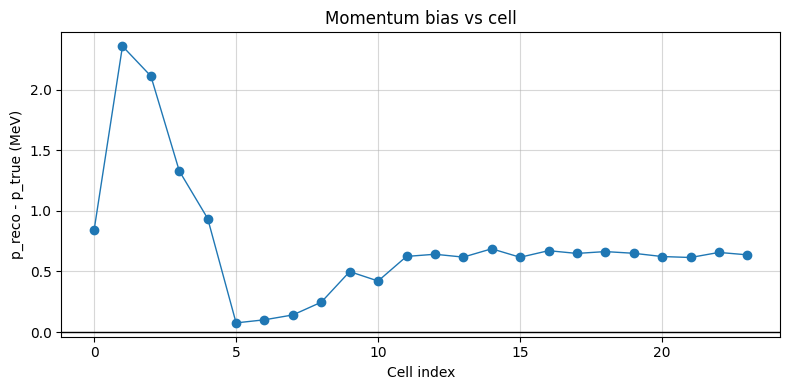

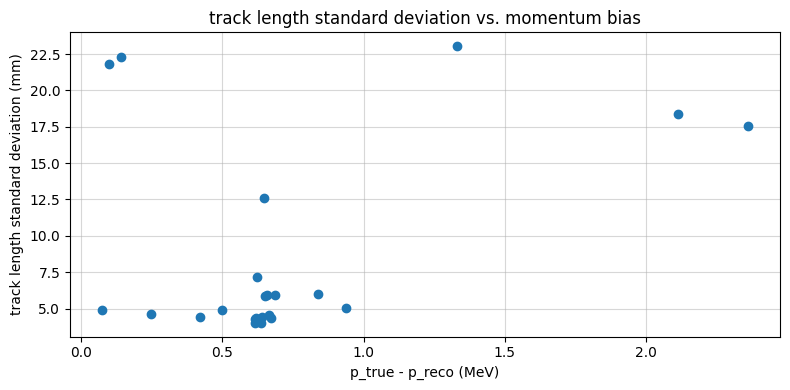

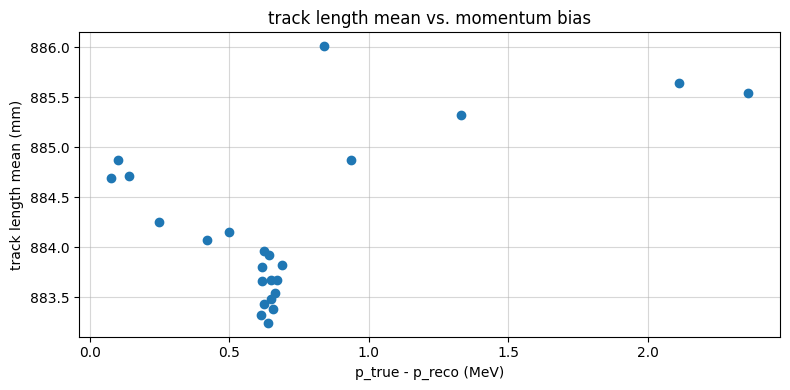

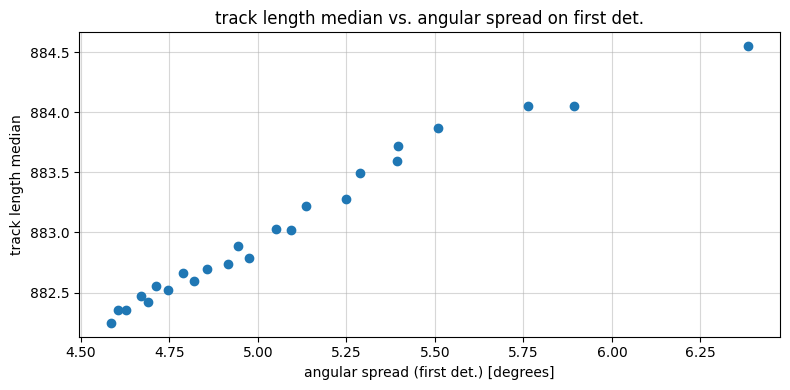

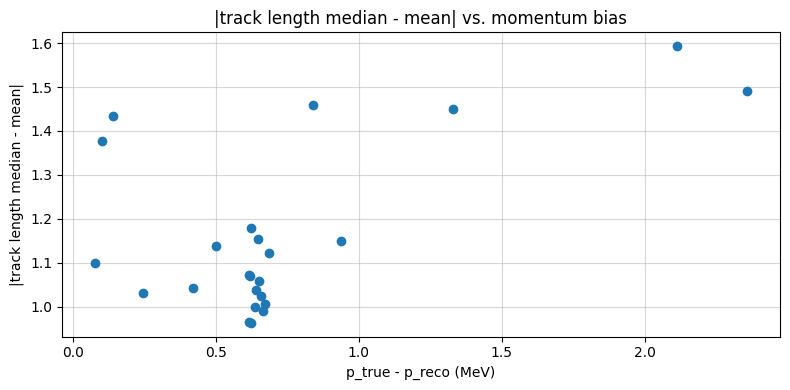

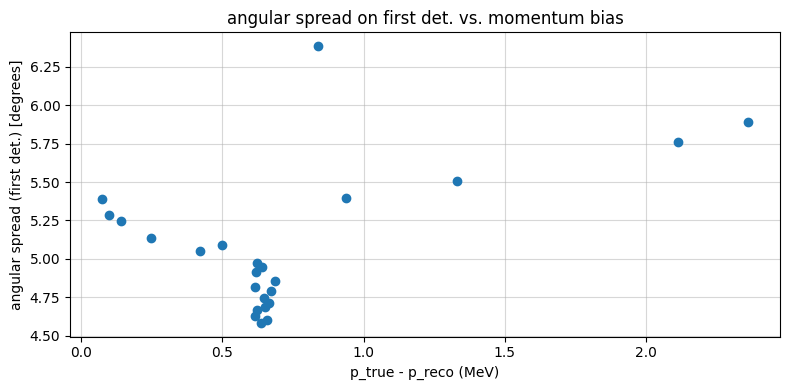

In [99]:
p_true = np.array(reco_p_true)
p_reco = np.array(reco_p_all)

dp = p_true - p_reco
rel_dp = dp / p_true

trlen_std = np.array(cell_trlen_stdev)
trlen_mean = np.array(cell_trlen_avgs_path)
trlen_norm = np.array(cell_trlen_norm_avgs)
trlen_median = np.array(cell_trlen_median)

angular_spread_0 = []
angular_spread_1 = []

for idx in range(24):
    angular_spread_0.append(mean_angular_spread[idx][0])
    angular_spread_1.append(mean_angular_spread[idx][1])

cell = np.arange(len(p_true))


# -----------------------------
# PLOT 1: Absolute momentum bias vs cell
# -----------------------------
plt.figure(figsize=(8,4))
plt.plot(cell, dp, 'o-', lw=1)
plt.axhline(0, color='k', lw=1)
plt.xlabel("Cell index")
plt.ylabel("p_reco - p_true (MeV)")
plt.title("Momentum bias vs cell")
plt.grid()
plt.tight_layout()


# -----------------------------
# PLOT 2: Relative bias vs cell
# -----------------------------
plt.figure(figsize=(8,4))
plt.plot(dp, trlen_std, 'o', lw=1)
# plt.axhline(0, color='k', lw=1)
plt.ylabel("track length standard deviation (mm)")
plt.xlabel("p_true - p_reco (MeV)")
plt.title("track length standard deviation vs. momentum bias")
plt.grid()
plt.tight_layout()


# -----------------------------
# PLOT 3: Track length mean
# -----------------------------
plt.figure(figsize=(8,4))
plt.plot(dp, trlen_mean, 'o', lw=1)
# plt.axhline(0, color='k', lw=1)
plt.ylabel("track length mean (mm)")
plt.xlabel("p_true - p_reco (MeV)")
plt.title("track length mean vs. momentum bias")
plt.grid()
plt.tight_layout()

# -----------------------------
# PLOT 4: Track length median
# -----------------------------
plt.figure(figsize=(8,4))
plt.plot(angular_spread_0, trlen_median, 'o', lw=1)
# plt.axhline(0, color='k', lw=1)
plt.ylabel("track length median")
plt.xlabel("angular spread (first det.) [degrees]")
plt.title("track length median vs. angular spread on first det.")
plt.grid()
plt.tight_layout()

# -----------------------------
# PLOT 5: Track length median - mean
# -----------------------------
plt.figure(figsize=(8,4))
plt.plot(dp, np.abs(trlen_median - trlen_mean), 'o', lw=1)
# plt.axhline(0, color='k', lw=1)
plt.ylabel("|track length median - mean|")
plt.xlabel("p_true - p_reco (MeV)")
plt.title("|track length median - mean| vs. momentum bias")
plt.grid()
plt.tight_layout()

# -----------------------------
# PLOT 5: angular spread (0)
# -----------------------------
plt.figure(figsize=(8,4))
plt.plot(dp, angular_spread_0, 'o', lw=1)
# plt.axhline(0, color='k', lw=1)
plt.ylabel("angular spread (first det.) [degrees]")
plt.xlabel("p_true - p_reco (MeV)")
plt.title("angular spread on first det. vs. momentum bias")
plt.grid()
plt.tight_layout()



plt.show()
